<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Harmonik genlik farkı ortalaması (Orijinal vs Gauss) : 0.8690
Harmonik genlik farkı ortalaması (Orijinal vs S&P)   : 1.0314


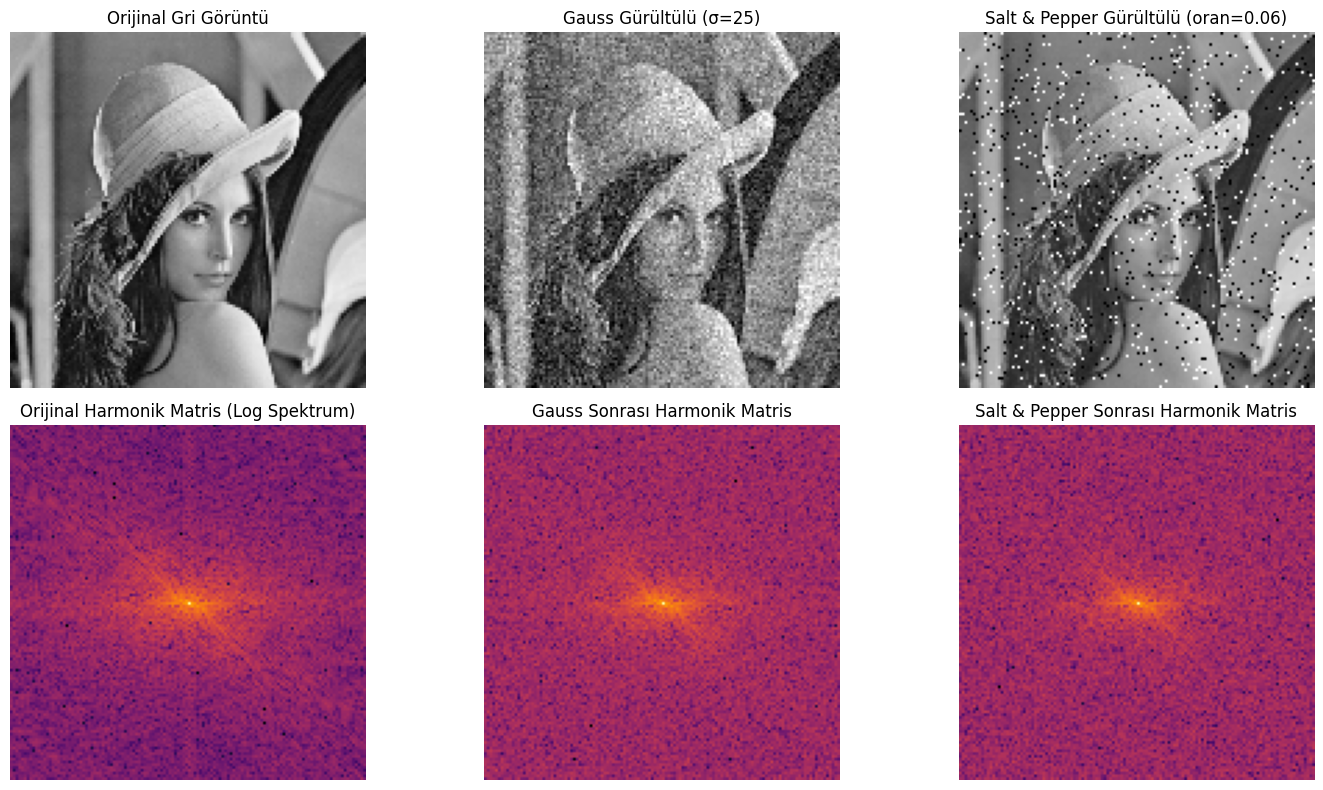

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def dft_1d_matrix(N):
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    return np.exp(-1j * 2.0 * np.pi * (n @ k) / N)

def dft_2d(image):
    img = np.asarray(image, dtype=np.float64)
    if img.ndim == 3:
        img = 0.114 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.299 * img[:, :, 2]
    M, N = img.shape
    return dft_1d_matrix(M) @ img @ dft_1d_matrix(N)

def gauss_gurultu_ekle(image, noise_strength=25.0, mean=0.0):
    """
    Görüntüye belirtilen standart sapma (noise_strength) kuvvetinde
    Gauss gürültüsü ekler.
    """
    img_float = np.asarray(image, dtype=np.float64)
    gauss_noise = np.random.normal(mean, noise_strength, size=img_float.shape)
    noisy = np.clip(img_float + gauss_noise, 0, 255)
    return noisy.astype(np.uint8)

def salt_and_pepper_ekle(image, noise_ratio=0.05, salt_vs_pepper=0.5):
    """
    Görüntüye [0, 1] aralığındaki noise_ratio oranında
    Salt-and-Pepper (tuz-biber) gürültüsü ekler.
    """
    if not (0.0 <= noise_ratio <= 1.0):
        raise ValueError("Gürültü oranı [0, 1] aralığında olmalıdır.")

    noisy = np.asarray(image, dtype=np.uint8).copy()
    rnd = np.random.rand(*noisy.shape)

    salt_mask = rnd < (noise_ratio * salt_vs_pepper)
    pepper_mask = (rnd >= (noise_ratio * salt_vs_pepper)) & (rnd < noise_ratio)

    noisy[salt_mask] = 255
    noisy[pepper_mask] = 0
    return noisy

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img_color = cv2.imdecode(arr, cv2.IMREAD_COLOR)

img_gray = cv2.cvtColor(cv2.resize(img_color, (128, 128)), cv2.COLOR_BGR2GRAY)

img_gauss = gauss_gurultu_ekle(img_gray, noise_strength=25.0)
img_sp = salt_and_pepper_ekle(img_gray, noise_ratio=0.06)

harm_orig = dft_2d(img_gray)
harm_gauss = dft_2d(img_gauss)
harm_sp = dft_2d(img_sp)

spec_orig = np.log1p(np.abs(np.fft.fftshift(harm_orig)))
spec_gauss = np.log1p(np.abs(np.fft.fftshift(harm_gauss)))
spec_sp = np.log1p(np.abs(np.fft.fftshift(harm_sp)))

diff_gauss_spec = np.abs(spec_orig - spec_gauss)
diff_sp_spec = np.abs(spec_orig - spec_sp)

print(f"Harmonik genlik farkı ortalaması (Orijinal vs Gauss) : {np.mean(diff_gauss_spec):.4f}")
print(f"Harmonik genlik farkı ortalaması (Orijinal vs S&P)   : {np.mean(diff_sp_spec):.4f}")

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Orijinal Gri Görüntü')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_gauss, cmap='gray')
plt.title('Gauss Gürültülü (σ=25)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_sp, cmap='gray')
plt.title('Salt & Pepper Gürültülü (oran=0.06)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(spec_orig, cmap='inferno')
plt.title('Orijinal Harmonik Matris (Log Spektrum)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(spec_gauss, cmap='inferno')
plt.title('Gauss Sonrası Harmonik Matris')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(spec_sp, cmap='inferno')
plt.title('Salt & Pepper Sonrası Harmonik Matris')
plt.axis('off')

plt.tight_layout()
plt.show()